# 01 — Self-supervised carotid ultrasound adaptation

This notebook builds the 2,840-image B-mode training pool and trains the two self-supervised representation-learning conditions used in the study: **EMA-based latent self-distillation inspired by I-JEPA** and a **MAE-style masked-reconstruction control**.


The notebook uses the CUBS and Orvile dataset locations defined below.


## Outputs

The notebook saves two encoder checkpoints:

1. `ijepa_corrected_2840_encoder.pth` — EMA-distillation encoder.
2. `mae_corrected_2840_encoder.pth` — MAE-style encoder.

The checkpoint filenames are retained for compatibility with the downstream notebooks.


## 1. Environment and paths

In [ ]:
!pip -q install timm scikit-learn pandas tqdm opencv-python pillow

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, re, glob, json, random, pickle, copy
import cv2, numpy as np, pandas as pd
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import timm, torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, precision_score, recall_score
from tqdm import tqdm
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(42)
print("Device:", DEVICE)

Device: cuda


In [ ]:
class Config:
    # Dataset locations
    CUBS_ROOT = "/content/drive/MyDrive/dataset cubs original/dataset cubs"
    ORVILE_ROOT = "/content/drive/MyDrive/dataset Orvile"
    ARPLAQUE_ROOT = "/content/drive/MyDrive/dataset Ar-PlaqSegm1"
    PROJECT_DIR = "/content/drive/MyDrive/IJEPA_Carotid_ViTS16"

    # Output directories for this experiment
    CLEAN_RUN = os.path.join(PROJECT_DIR, "clean_2840_20260930")
    CHECKPOINT_DIR = os.path.join(CLEAN_RUN, "checkpoints")
    RESULT_DIR = os.path.join(CLEAN_RUN, "results")
    MANIFEST_DIR = os.path.join(CLEAN_RUN, "manifests")
    STATE_DIR = os.path.join(CLEAN_RUN, "resume_state")
    REVIEW_DIR = os.path.join(CLEAN_RUN, "review")

    ARCH = "vit_small_patch16_224"
    IMG_SIZE = 224
    SSL_SEED = 42
    DOWNSTREAM_SEEDS = [42,43,44]
    SSL_EPOCHS = 15
    SSL_BATCH_SIZE = 16
    SSL_LR = 1.5e-4
    SSL_EMA = 0.996

for p in [Config.CLEAN_RUN,Config.CHECKPOINT_DIR,Config.RESULT_DIR,Config.MANIFEST_DIR,Config.STATE_DIR,Config.REVIEW_DIR]:
    os.makedirs(p,exist_ok=True)
print("Legacy project root (reused):", Config.PROJECT_DIR)
print("New outputs only:", Config.CLEAN_RUN)

Legacy project root (reused): /content/drive/MyDrive/IJEPA_Carotid_ViTS16
New outputs only: /content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930


## 2. CUBS participant split and grayscale proxy labels

In [ ]:
# Build CUBS preprocessing cache
VALID_EXTS=(".png",".jpg",".jpeg",".tiff",".tif",".bmp")
CUBS_IMAGE_DIR=os.path.join(Config.CUBS_ROOT,"IMAGES")
CUBS_SEG_DIR=os.path.join(Config.CUBS_ROOT,"SEGMENTATIONS")
cubs_image_paths=sorted(p for p in glob.glob(os.path.join(CUBS_IMAGE_DIR,"*.*")) if p.lower().endswith(VALID_EXTS))
mask_txt_paths=sorted(p for p in glob.glob(os.path.join(CUBS_SEG_DIR,"**","*.txt"),recursive=True) if "manual-a1" in p.lower().replace("'","") and "manual-a1'" not in p.lower())
mask_groups={}
for mp in mask_txt_paths:
    base=os.path.splitext(os.path.basename(mp))[0].lower()
    if base.endswith('_rect'): stem,typ=base[:-5].rstrip('_'),'rect'
    elif '-li' in base: stem,typ=base.replace('-li',''),'LI'
    elif '-ma' in base: stem,typ=base.replace('-ma',''),'MA'
    else: continue
    mask_groups.setdefault(stem,{})[typ]=mp

def parse_polygon(path):
    pts=[]
    with open(path) as f:
        for line in f:
            z=line.strip().split()
            if len(z)>=2:
                try: pts.append((float(z[0]),float(z[1])))
                except: pass
    return np.asarray(pts,dtype=np.float32)
def parse_rect(path):
    try:
        with open(path) as f: return tuple(float(x) for x in next(x for x in f if x.strip()).split()[:4])
    except: return None
def rect_to_mask(rect,shape):
    if rect is None:return None
    x,y,w,h=rect; H,W=shape; x1,y1=max(0,round(x)),max(0,round(y)); x2,y2=min(W,round(x+w)),min(H,round(y+h))
    if x1>=x2 or y1>=y2:return None
    m=np.zeros(shape,dtype=bool);m[y1:y2,x1:x2]=True;return m
def build_wall_mask(li_path,ma_path,shape):
    li,ma=parse_polygon(li_path),parse_polygon(ma_path)
    if len(li)<2 or len(ma)<2:return None
    H,W=shape;pts=np.round(np.vstack([li,ma[::-1]])).astype(np.int32);pts[:,0]=np.clip(pts[:,0],0,W-1);pts[:,1]=np.clip(pts[:,1],0,H-1)
    m=np.zeros((H,W),dtype=np.uint8);cv2.fillPoly(m,[pts],255);m=m>0;return m if m.sum()>=10 else None

cubs_records=[]
for img_path in tqdm(cubs_image_paths,desc='CUBS preprocessing'):
    basename=os.path.basename(img_path);stem=os.path.splitext(basename)[0].lower();g=mask_groups.get(stem)
    if not g: continue
    gray=np.asarray(Image.open(img_path).convert('L')); wall=build_wall_mask(g['LI'],g['MA'],gray.shape) if ('LI'in g and 'MA'in g) else None
    if wall is not None: value,source=float(gray[wall].mean()),'wall'
    elif 'rect' in g and (rm:=rect_to_mask(parse_rect(g['rect']),gray.shape)) is not None: value,source=float(gray[rm].mean()),'rect'
    else:
        h,w=gray.shape;value,source=float(gray[h//4:3*h//4,w//4:3*w//4].mean()),'center-crop'
    m=re.search(r'clin[_-]?\d+',basename,re.I);pid=m.group(0).lower() if m else stem
    cubs_records.append({'image_path':img_path,'patient_id':pid,'proxy_raw':value,'mask_source':source})

patients=np.unique([r['patient_id'] for r in cubs_records])
train_patients,held=train_test_split(patients,test_size=.20,random_state=42)
val_patients,test_patients=train_test_split(held,test_size=.50,random_state=42)
train_set,val_set,test_set=map(set,[train_patients,val_patients,test_patients])
cubs_train_records=[r for r in cubs_records if r['patient_id'] in train_set]
cubs_val_records=[r for r in cubs_records if r['patient_id'] in val_set]
cubs_test_records=[r for r in cubs_records if r['patient_id'] in test_set]
proxy_threshold=float(np.median([r['proxy_raw'] for r in cubs_train_records]))
for r in cubs_records:r['binary_label']=int(r['proxy_raw']>=proxy_threshold)
assert len(cubs_records)==2176, f'Expected 2176 CUBS images, found {len(cubs_records)}'
assert len(cubs_train_records)==1740, f'Expected 1740 CUBS train images, found {len(cubs_train_records)}'
assert not (train_set&val_set or train_set&test_set or val_set&test_set)
cache={'cubs_records':cubs_records,'cubs_train_records':cubs_train_records,'cubs_val_records':cubs_val_records,'cubs_test_records':cubs_test_records,'train_patients':train_patients,'val_patients':val_patients,'test_patients':test_patients,'proxy_threshold':proxy_threshold}
cache_path=os.path.join(Config.MANIFEST_DIR,'cubs_processed_split_clean.pkl')
with open(cache_path,'wb') as f:pickle.dump(cache,f)
print('CUBS train/val/test:',len(cubs_train_records),len(cubs_val_records),len(cubs_test_records));print('Saved NEW cache:',cache_path)

KeyboardInterrupt: 

In [ ]:
# Load cached CUBS preprocessing results
cache_path = os.path.join(
    Config.MANIFEST_DIR,
    'cubs_processed_split_clean.pkl'
)

assert os.path.exists(cache_path), f"Saved CUBS cache not found: {cache_path}"

with open(cache_path, 'rb') as f:
    cache = pickle.load(f)

cubs_records       = cache['cubs_records']
cubs_train_records = cache['cubs_train_records']
cubs_val_records   = cache['cubs_val_records']
cubs_test_records  = cache['cubs_test_records']

train_patients = cache['train_patients']
val_patients   = cache['val_patients']
test_patients  = cache['test_patients']
proxy_threshold = cache['proxy_threshold']

train_set = set(train_patients)
val_set   = set(val_patients)
test_set  = set(test_patients)

# Verify cached data
assert len(cubs_records) == 2176
assert len(cubs_train_records) == 1740
assert len(cubs_val_records) == 218
assert len(cubs_test_records) == 218
assert not (train_set & val_set or
            train_set & test_set or
            val_set & test_set)

print("Loaded existing CUBS preprocessing cache:")
print(cache_path)
print()
print("CUBS total:", len(cubs_records))
print("CUBS train:", len(cubs_train_records))
print("CUBS val:", len(cubs_val_records))
print("CUBS test:", len(cubs_test_records))
print("Proxy threshold:", proxy_threshold)
print()
print("✓ Existing preprocessing reused — no CUBS images reprocessed.")

Loaded existing CUBS preprocessing cache:
/content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/manifests/cubs_processed_split_clean.pkl

CUBS total: 2176
CUBS train: 1740
CUBS val: 218
CUBS test: 218
Proxy threshold: 60.265848031669435

✓ Existing preprocessing reused — no CUBS images reprocessed.


## 3. Orvile B-mode discovery and audit of the 2,840-image SSL pool

In [ ]:
# Identify Orvile B-mode images
all_orvile=sorted(p for p in glob.glob(os.path.join(Config.ORVILE_ROOT,'**','*.*'),recursive=True) if p.lower().endswith(VALID_EXTS))
MASK_TERMS=('mask','masks','segmentation','segmentations','groundtruth','ground_truth','ground-truth','label','labels','_gt','/gt/','\\gt\\')
def looks_like_mask_path(p):
    q=p.lower().replace('\\','/')
    return any(term.replace('\\','/') in q for term in MASK_TERMS)
orvile_paths=[p for p in all_orvile if not looks_like_mask_path(p)]
rejected=[p for p in all_orvile if looks_like_mask_path(p)]
print('All Orvile image-like files:',len(all_orvile));print('Accepted B-mode:',len(orvile_paths));print('Rejected mask/label paths:',len(rejected))
if len(orvile_paths)!=1100:
    print('\nAccepted path examples:');print(*orvile_paths[:10],sep='\n')
    print('\nRejected path examples:');print(*rejected[:10],sep='\n')
    raise RuntimeError(f'STOP: expected exactly 1100 Orvile B-mode images, found {len(orvile_paths)}. Inspect folder naming before training.')
cubs_ssl_paths=[r['image_path'] for r in cubs_train_records]
ssl_paths=cubs_ssl_paths+orvile_paths
assert len(cubs_ssl_paths)==1740 and len(orvile_paths)==1100 and len(ssl_paths)==2840
assert not set(r['image_path'] for r in cubs_val_records)&set(ssl_paths)
assert not set(r['image_path'] for r in cubs_test_records)&set(ssl_paths)
assert not any(looks_like_mask_path(p) for p in orvile_paths)
manifest={'study':'corrected B-mode-only carotid SSL','run_namespace':Config.CLEAN_RUN,'ssl_seed':Config.SSL_SEED,'counts':{'cubs_train_bmode':1740,'orvile_bmode':1100,'total':2840},'cubs_train_patients':sorted(train_set),'cubs_val_patients':sorted(val_set),'cubs_test_patients':sorted(test_set),'ssl_sources':{'cubs_train':cubs_ssl_paths,'orvile_bmode':orvile_paths},'explicitly_excluded':['CUBS validation/test','Orvile masks','Ar-PlaqSegm1']}
manifest_path=os.path.join(Config.MANIFEST_DIR,'ssl_corrected_2840_manifest.json')
with open(manifest_path,'w') as f:json.dump(manifest,f,indent=2)
print('AUDIT PASSED: 1740 + 1100 =',len(ssl_paths));print('Manifest:',manifest_path)

All Orvile image-like files: 2200
Accepted B-mode: 1100
Rejected mask/label paths: 1100
AUDIT PASSED: 1740 + 1100 = 2840
Manifest: /content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/manifests/ssl_corrected_2840_manifest.json


In [ ]:
manifest_path = os.path.join(
    Config.MANIFEST_DIR,
    'ssl_corrected_2840_manifest.json'
)

assert os.path.exists(manifest_path), \
    f"Corrected SSL manifest not found: {manifest_path}"

with open(manifest_path, 'r') as f:
    manifest = json.load(f)

# Load the saved SSL image manifest
cubs_ssl_paths = manifest['ssl_sources']['cubs_train']
orvile_paths   = manifest['ssl_sources']['orvile_bmode']
ssl_paths      = cubs_ssl_paths + orvile_paths

# Verify manifest contents
assert len(cubs_ssl_paths) == 1740, len(cubs_ssl_paths)
assert len(orvile_paths) == 1100, len(orvile_paths)
assert len(ssl_paths) == 2840, len(ssl_paths)

# Check that all manifest files are available
missing = [p for p in ssl_paths if not os.path.exists(p)]
assert len(missing) == 0, \
    f"STOP: {len(missing)} SSL files from the saved manifest are missing."

# Check CUBS participant split
val_paths  = set(r['image_path'] for r in cubs_val_records)
test_paths = set(r['image_path'] for r in cubs_test_records)

assert not val_paths.intersection(ssl_paths)
assert not test_paths.intersection(ssl_paths)

# Exclude mask files from the Orvile pool
MASK_TERMS = (
    'mask', 'masks',
    'segmentation', 'segmentations',
    'groundtruth', 'ground_truth', 'ground-truth',
    'label', 'labels',
    '_gt', '/gt/', '\\gt\\'
)

def looks_like_mask_path(p):
    q = p.lower().replace('\\', '/')
    return any(term.replace('\\', '/') in q for term in MASK_TERMS)

assert not any(looks_like_mask_path(p) for p in orvile_paths), \
    "STOP: a mask-like Orvile path exists in the saved manifest."

print("Loaded existing corrected SSL manifest:")
print(manifest_path)
print()
print("CUBS train B-mode:", len(cubs_ssl_paths))
print("Orvile B-mode:", len(orvile_paths))
print("Total SSL pool:", len(ssl_paths))
print("Missing files:", len(missing))
print("Orvile mask-like paths:",
      sum(looks_like_mask_path(p) for p in orvile_paths))
print()
print("✓ AUDIT PASSED: existing 2,840-image B-mode-only manifest reused.")

Loaded existing corrected SSL manifest:
/content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/manifests/ssl_corrected_2840_manifest.json

CUBS train B-mode: 1740
Orvile B-mode: 1100
Total SSL pool: 2840
Missing files: 0
Orvile mask-like paths: 0

✓ AUDIT PASSED: existing 2,840-image B-mode-only manifest reused.


## 4. EMA-based latent self-distillation (I-JEPA-inspired)

In [ ]:
IMAGENET_MEAN=(0.485,0.456,0.406);IMAGENET_STD=(0.229,0.224,0.225)
ssl_transform=T.Compose([T.RandomResizedCrop(224,scale=(.35,1.0)),T.RandomHorizontalFlip(),T.RandomApply([T.ColorJitter(.25,.25,.15,.05)],p=.6),T.RandomGrayscale(p=.15),T.ToTensor(),T.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
class SSLDataset(Dataset):
    def __init__(self,paths):self.paths=list(paths)
    def __len__(self):return len(self.paths)
    def __getitem__(self,i):return ssl_transform(Image.open(self.paths[i]).convert('RGB'))
class Predictor(nn.Module):
    def __init__(self,dim):super().__init__();self.net=nn.Sequential(nn.Linear(dim,dim),nn.GELU(),nn.Linear(dim,dim))
    def forward(self,x):return self.net(x)
def build_ssl_components():
    enc=timm.create_model(Config.ARCH,pretrained=True,num_classes=0).to(DEVICE);tgt=timm.create_model(Config.ARCH,pretrained=True,num_classes=0).to(DEVICE);tgt.load_state_dict(enc.state_dict())
    for p in tgt.parameters():p.requires_grad=False
    return enc,tgt,Predictor(enc.num_features).to(DEVICE)
def patch_tokens(model,x):
    z=model.forward_features(x);return z[:,getattr(model,'num_prefix_tokens',1):,:]
@torch.no_grad()
def ema_update(t,o,m):
    for pt,po in zip(t.parameters(),o.parameters()):pt.data.mul_(m).add_(po.data,alpha=1-m)

def train_ssl():
    set_seed(Config.SSL_SEED);online,target,predictor=build_ssl_components();opt=torch.optim.AdamW(list(online.parameters())+list(predictor.parameters()),lr=Config.SSL_LR,weight_decay=.05);sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=Config.SSL_EPOCHS);scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
    state_file=os.path.join(Config.STATE_DIR,'ssl_corrected_2840_latest.pth');history=[];start=0
    if os.path.exists(state_file):
        ck=torch.load(state_file,map_location=DEVICE);online.load_state_dict(ck['online']);target.load_state_dict(ck['target']);predictor.load_state_dict(ck['predictor']);opt.load_state_dict(ck['optimizer']);sched.load_state_dict(ck['scheduler']);history=ck.get('history',[]);start=ck['epoch']+1;print('Resume epoch',start+1)
    loader=DataLoader(SSLDataset(ssl_paths),batch_size=Config.SSL_BATCH_SIZE,shuffle=True,num_workers=0,drop_last=True)
    for epoch in range(start,Config.SSL_EPOCHS):
        online.train();predictor.train();losses=[]
        for x in tqdm(loader,desc=f'SSL {epoch+1}/{Config.SSL_EPOCHS}'):
            x=x.to(DEVICE);opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                zo=patch_tokens(online,x)
                with torch.no_grad():zt=patch_tokens(target,x)
                P=zo.shape[1];n=max(1,int(.20*P));idx=torch.randperm(P,device=DEVICE)[:n];loss=F.smooth_l1_loss(predictor(zo[:,idx,:]),zt[:,idx,:].detach())
            scaler.scale(loss).backward();scaler.step(opt);scaler.update();ema_update(target,online,Config.SSL_EMA);losses.append(loss.item())
        sched.step();history.append(float(np.mean(losses)));print('loss',history[-1])
        torch.save({'epoch':epoch,'online':online.state_dict(),'target':target.state_dict(),'predictor':predictor.state_dict(),'optimizer':opt.state_dict(),'scheduler':sched.state_dict(),'history':history,'manifest':manifest_path},state_file)
        pd.DataFrame({'epoch':range(1,len(history)+1),'ssl_loss':history}).to_csv(os.path.join(Config.REVIEW_DIR,'ssl_corrected_2840_history.csv'),index=False)
    final=os.path.join(Config.CHECKPOINT_DIR,'ijepa_corrected_2840_encoder.pth');torch.save({'encoder_state_dict':online.state_dict(),'arch':Config.ARCH,'ssl_sources':'1740 CUBS train B-mode + 1100 Orvile B-mode','n_ssl_images':2840,'manifest':manifest_path,'history':history},final);print('FINAL:',final)
    return final

## 5. Train the EMA-distillation model

In [ ]:
RUN_SSL=True
if RUN_SSL:
    FINAL_CHECKPOINT=train_ssl()
else:
    print('Pre-flight complete. Confirm counts above, then set RUN_SSL=True.')

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_513/306344616.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  set_seed(Config.SSL_SEED);online,target,predictor=build_ssl_components();opt=torch.optim.AdamW(list(online.parameters())+list(predictor.parameters()),lr=Config.SSL_LR,weight_decay=.05);sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=Config.SSL_EPOCHS);scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
SSL 1/15:   0%|          | 0/177 [00:00<?, ?it/s]/tmp/ipykernel_513/306344616.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
SSL 1/15: 100%|██████████| 177/177 [16:26<00:00,  5.58s/it]


loss 0.5510054703822918


SSL 2/15: 100%|██████████| 177/177 [00:55<00:00,  3.22it/s]


...

loss 0.26757840214476075


SSL 14/15: 100%|██████████| 177/177 [00:54<00:00,  3.25it/s]


loss 0.2874377255385878


SSL 15/15: 100%|██████████| 177/177 [00:54<00:00,  3.24it/s]


loss 0.3120510849238789
FINAL: /content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/checkpoints/ijepa_corrected_2840_encoder.pth


 epoch  ssl_loss
     1  0.551005
     2  0.248998
     3  0.217232
     4  0.211400
     5  0.216353
     6  0.219303
     7  0.226395
     8  0.227582
     9  0.228749
    10  0.233672
    11  0.240805
    12  0.252320
    13  0.267578
    14  0.287438
    15  0.312051

Minimum SSL loss: 0.211400
Minimum-loss epoch: 4


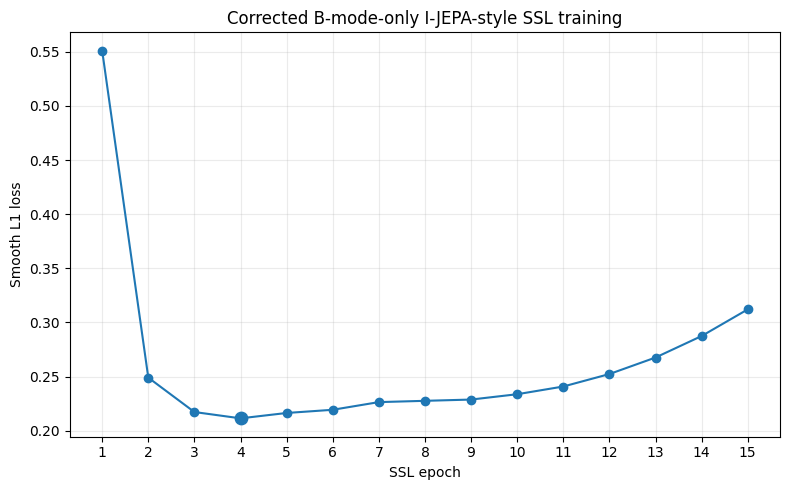

Saved figure: /content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/review/ssl_corrected_2840_loss_curve.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

history_path = os.path.join(
    Config.REVIEW_DIR,
    'ssl_corrected_2840_history.csv'
)

df = pd.read_csv(history_path)

# Minimum training loss
min_idx = df['ssl_loss'].idxmin()
min_epoch = int(df.loc[min_idx, 'epoch'])
min_loss = float(df.loc[min_idx, 'ssl_loss'])

print(df.to_string(index=False))
print()
print(f"Minimum SSL loss: {min_loss:.6f}")
print(f"Minimum-loss epoch: {min_epoch}")

# Training-loss curve
plt.figure(figsize=(8, 5))
plt.plot(df['epoch'], df['ssl_loss'], marker='o')
plt.scatter([min_epoch], [min_loss], s=80, zorder=3)

plt.xlabel('SSL epoch')
plt.ylabel('Smooth L1 loss')
plt.title('Corrected B-mode-only I-JEPA-style SSL training')
plt.xticks(df['epoch'])
plt.grid(alpha=0.25)
plt.tight_layout()

figure_path = os.path.join(
    Config.REVIEW_DIR,
    'ssl_corrected_2840_loss_curve.png'
)

plt.savefig(figure_path, dpi=300, bbox_inches='tight')
plt.show()

print("Saved figure:", figure_path)

In [ ]:
# MAE-style SSL control using the same 2,840-image B-mode training pool

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import timm

MAE_SEED = 42
MAE_EPOCHS = 15
MAE_BATCH_SIZE = 16
MAE_LR = 1.5e-4
MAE_WD = 0.05
MAE_MASK_RATIO = 0.75
PATCH_SIZE = 16
IMAGE_SIZE = 224

random.seed(MAE_SEED)
np.random.seed(MAE_SEED)
torch.manual_seed(MAE_SEED)
torch.cuda.manual_seed_all(MAE_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MAE_STATE = os.path.join(
    Config.STATE_DIR,
    "mae_corrected_2840_latest.pth"
)

MAE_ENCODER = os.path.join(
    Config.CHECKPOINT_DIR,
    "mae_corrected_2840_encoder.pth"
)

MAE_HISTORY = os.path.join(
    Config.REVIEW_DIR,
    "mae_corrected_2840_history.csv"
)

MAE_CURVE = os.path.join(
    Config.REVIEW_DIR,
    "mae_corrected_2840_loss_curve.png"
)

print("Device:", device)
print("MAE training images:", len(ssl_paths))

assert len(ssl_paths) == 2840, \
    f"Expected clean 2,840-image pool, got {len(ssl_paths)}"

print("Clean MAE configuration ready.")

Device: cuda
MAE training images: 2840
Clean MAE configuration ready.


In [ ]:
# MAE dataset and patchification

imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std  = (0.229, 0.224, 0.225)

mae_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.35, 1.0)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])


class MAEDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        return self.transform(img)


def patchify(imgs, patch_size=16):
    """
    imgs: [B, 3, H, W]
    returns: [B, N, patch_size*patch_size*3]
    """
    B, C, H, W = imgs.shape

    assert H == W
    assert H % patch_size == 0

    h = w = H // patch_size

    x = imgs.reshape(
        B, C, h, patch_size, w, patch_size
    )

    x = torch.einsum(
        "bchpwq->bhwpqc", x
    )

    patches = x.reshape(
        B, h * w, patch_size * patch_size * C
    )

    return patches


mae_dataset = MAEDataset(
    ssl_paths,
    mae_transform
)

mae_loader = DataLoader(
    mae_dataset,
    batch_size=MAE_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

print("MAE dataset:", len(mae_dataset))
print("Batches/epoch:", len(mae_loader))

MAE dataset: 2840
Batches/epoch: 177


In [ ]:
# MAE-style masked reconstruction model

class MAEStyleModel(nn.Module):

    def __init__(
        self,
        arch="vit_small_patch16_224",
        patch_size=16
    ):
        super().__init__()

        # Initialize the ViT-S/16 encoder from ImageNet weights
        self.encoder = timm.create_model(
            arch,
            pretrained=True,
            num_classes=0
        )

        self.patch_size = patch_size
        self.embed_dim = self.encoder.embed_dim

        self.mask_token = nn.Parameter(
            torch.zeros(1, 1, self.embed_dim)
        )

        nn.init.normal_(
            self.mask_token,
            std=0.02
        )

        # Reconstruct RGB values for each 16x16 patch
        patch_dim = patch_size * patch_size * 3

        self.decoder = nn.Sequential(
            nn.Linear(self.embed_dim, self.embed_dim),
            nn.GELU(),
            nn.Linear(self.embed_dim, patch_dim)
        )

    def forward(self, imgs, mask_ratio=0.75):

        # Patch embeddings
        x = self.encoder.patch_embed(imgs)

        B, N, D = x.shape

        # Sample an independent random mask for each image
        num_mask = int(N * mask_ratio)

        noise = torch.rand(
            B, N,
            device=x.device
        )

        ids = torch.argsort(
            noise,
            dim=1
        )

        mask = torch.zeros(
            B, N,
            dtype=torch.bool,
            device=x.device
        )

        mask.scatter_(
            1,
            ids[:, :num_mask],
            True
        )

        # Replace masked patch embeddings with the learned mask token
        mask_tokens = self.mask_token.expand(
            B, N, -1
        )

        x = torch.where(
            mask.unsqueeze(-1),
            mask_tokens,
            x
        )

        # Add class token
        cls_token = self.encoder.cls_token.expand(
            B, -1, -1
        )

        x = torch.cat(
            (cls_token, x),
            dim=1
        )

        # Add positional embeddings
        x = x + self.encoder.pos_embed

        x = self.encoder.pos_drop(x)

        # Transformer blocks
        for blk in self.encoder.blocks:
            x = blk(x)

        x = self.encoder.norm(x)

        # Remove class token
        patch_tokens = x[:, 1:, :]

        # Reconstruct image patches
        pred = self.decoder(patch_tokens)

        return pred, mask


mae_model = MAEStyleModel(
    arch=Config.ARCH,
    patch_size=PATCH_SIZE
).to(device)

n_params = sum(
    p.numel()
    for p in mae_model.parameters()
)

print(
    f"MAE-style model created: {n_params/1e6:.2f}M parameters"
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

MAE-style model created: 22.11M parameters


In [ ]:
# Train MAE-style SSL

optimizer = torch.optim.AdamW(
    mae_model.parameters(),
    lr=MAE_LR,
    weight_decay=MAE_WD
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAE_EPOCHS
)

criterion = nn.MSELoss()

start_epoch = 0
history = []

# Resume from the experiment checkpoint if available
if os.path.exists(MAE_STATE):

    print("Found CLEAN MAE resume state.")

    state = torch.load(
        MAE_STATE,
        map_location=device
    )

    mae_model.load_state_dict(
        state["model_state_dict"]
    )

    optimizer.load_state_dict(
        state["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        state["scheduler_state_dict"]
    )

    start_epoch = state["epoch"] + 1
    history = state["history"]

    print(
        f"Resuming from epoch {start_epoch + 1}"
    )

else:
    print(
        "No clean MAE resume state found."
    )
    print(
        "Starting fresh from ImageNet initialization."
    )


for epoch in range(start_epoch, MAE_EPOCHS):

    mae_model.train()

    running_loss = 0.0
    n_batches = 0

    for imgs in mae_loader:

        imgs = imgs.to(
            device,
            non_blocking=True
        )

        targets = patchify(
            imgs,
            PATCH_SIZE
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        pred, mask = mae_model(
            imgs,
            mask_ratio=MAE_MASK_RATIO
        )

        # Compute MSE over masked patches
        loss = criterion(
            pred[mask],
            targets[mask]
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        n_batches += 1

    scheduler.step()

    epoch_loss = (
        running_loss / n_batches
    )

    history.append({
        "epoch": epoch + 1,
        "loss": epoch_loss,
        "lr": optimizer.param_groups[0]["lr"]
    })

    print(
        f"Epoch {epoch+1:02d}/{MAE_EPOCHS} "
        f"| loss={epoch_loss:.6f} "
        f"| lr={optimizer.param_groups[0]['lr']:.8f}"
    )

    # Save resume state after each epoch
    torch.save({
        "epoch": epoch,
        "model_state_dict":
            mae_model.state_dict(),
        "optimizer_state_dict":
            optimizer.state_dict(),
        "scheduler_state_dict":
            scheduler.state_dict(),
        "history": history,
        "n_ssl_images": len(ssl_paths),
        "mask_ratio": MAE_MASK_RATIO,
        "source":
            "corrected_2840_bmode_only"
    }, MAE_STATE)

    pd.DataFrame(history).to_csv(
        MAE_HISTORY,
        index=False
    )


print("MAE training complete.")

No clean MAE resume state found.
Starting fresh from ImageNet initialization.
Epoch 01/15 | loss=0.626438 | lr=0.00014836
Epoch 02/15 | loss=0.352333 | lr=0.00014352
Epoch 03/15 | loss=0.328267 | lr=0.00013568
Epoch 04/15 | loss=0.316149 | lr=0.00012518
Epoch 05/15 | loss=0.306589 | lr=0.00011250
Epoch 06/15 | loss=0.289723 | lr=0.00009818
Epoch 07/15 | loss=0.280153 | lr=0.00008284
Epoch 08/15 | loss=0.264063 | lr=0.00006716
Epoch 09/15 | loss=0.241424 | lr=0.00005182
Epoch 10/15 | loss=0.230492 | lr=0.00003750
Epoch 11/15 | loss=0.223259 | lr=0.00002482
Epoch 12/15 | loss=0.221544 | lr=0.00001432
Epoch 13/15 | loss=0.215753 | lr=0.00000648
Epoch 14/15 | loss=0.218050 | lr=0.00000164
Epoch 15/15 | loss=0.212876 | lr=0.00000000
MAE training complete.


In [ ]:
# Save the prespecified epoch-15 MAE encoder

assert len(history) == MAE_EPOCHS, \
    "MAE training has not completed all 15 epochs."

torch.save({
    "encoder_state_dict":
        mae_model.encoder.state_dict(),

    "arch":
        Config.ARCH,

    "initialization":
        "ImageNet pretrained",

    "ssl_method":
        "MAE-style masked patch reconstruction",

    "mask_ratio":
        MAE_MASK_RATIO,

    "ssl_epochs":
        MAE_EPOCHS,

    "n_ssl_images":
        len(ssl_paths),

    "ssl_pool":
        "1740 CUBS train B-mode + 1100 Orvile B-mode",

    "orvile_masks_included":
        False,

    "source":
        "corrected_2840_bmode_only",

    "history":
        history

}, MAE_ENCODER)

print("Saved clean MAE encoder:")
print(MAE_ENCODER)

Saved clean MAE encoder:
/content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/checkpoints/mae_corrected_2840_encoder.pth


,epoch,loss,lr
0,1,0.626438,0.000148
1,2,0.352333,0.000144
2,3,0.328267,0.000136
3,4,0.316149,0.000125
4,5,0.306589,0.000112
5,6,0.289723,0.000098
6,7,0.280153,0.000083
7,8,0.264063,0.000067
8,9,0.241424,0.000052
9,10,0.230492,0.000038


Minimum MAE training loss: 0.212876 at epoch 15


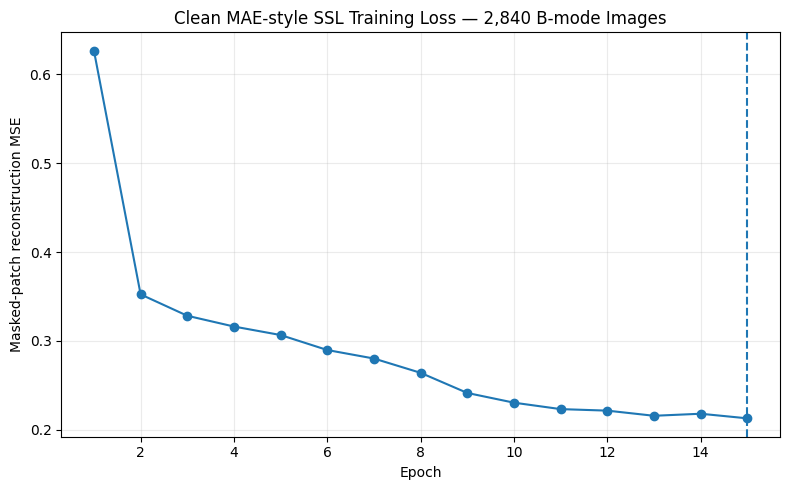

Saved: /content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/review/mae_corrected_2840_loss_curve.png


In [ ]:
# MAE training dynamics

hist = pd.read_csv(MAE_HISTORY)

display(hist)

best_idx = hist["loss"].idxmin()

best_epoch = int(
    hist.loc[best_idx, "epoch"]
)

best_loss = float(
    hist.loc[best_idx, "loss"]
)

print(
    f"Minimum MAE training loss: "
    f"{best_loss:.6f} at epoch {best_epoch}"
)

plt.figure(figsize=(8, 5))

plt.plot(
    hist["epoch"],
    hist["loss"],
    marker="o"
)

plt.axvline(
    best_epoch,
    linestyle="--"
)

plt.xlabel("Epoch")
plt.ylabel("Masked-patch reconstruction MSE")
plt.title(
    "Clean MAE-style SSL Training Loss — 2,840 B-mode Images"
)

plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    MAE_CURVE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", MAE_CURVE)

In [ ]:
# Check saved checkpoints and training histories

IJEPA_ENCODER = os.path.join(
    Config.CHECKPOINT_DIR,
    "ijepa_corrected_2840_encoder.pth"
)

print("=" * 65)
print("CLEAN REPRESENTATION PRETRAINING AUDIT")
print("=" * 65)

print("\nSSL POOL")
print("  CUBS training B-mode : 1740")
print("  Orvile B-mode        : 1100")
print("  Orvile masks         : 0")
print("  TOTAL                : 2840")

assert len(ssl_paths) == 2840
assert os.path.exists(IJEPA_ENCODER)
assert os.path.exists(MAE_ENCODER)

print("\nI-JEPA-STYLE")
print("  Architecture         :", Config.ARCH)
print("  Initialization       : ImageNet")
print("  SSL images           : 2840")
print("  SSL epochs           : 15")
print("  Final checkpoint     :", IJEPA_ENCODER)

print("\nMAE-STYLE")
print("  Architecture         :", Config.ARCH)
print("  Initialization       : ImageNet")
print("  SSL images           : 2840")
print("  Mask ratio           :", MAE_MASK_RATIO)
print("  SSL epochs           :", MAE_EPOCHS)
print("  Final checkpoint     :", MAE_ENCODER)

print("\n" + "=" * 65)
print("AUDIT PASSED")
print("NO ORVILE SEGMENTATION MASKS USED FOR SSL")
print("=" * 65)

CLEAN REPRESENTATION PRETRAINING AUDIT

SSL POOL
  CUBS training B-mode : 1740
  Orvile B-mode        : 1100
  Orvile masks         : 0
  TOTAL                : 2840

I-JEPA-STYLE
  Architecture         : vit_small_patch16_224
  Initialization       : ImageNet
  SSL images           : 2840
  SSL epochs           : 15
  Final checkpoint     : /content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/checkpoints/ijepa_corrected_2840_encoder.pth

MAE-STYLE
  Architecture         : vit_small_patch16_224
  Initialization       : ImageNet
  SSL images           : 2840
  Mask ratio           : 0.75
  SSL epochs           : 15
  Final checkpoint     : /content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/checkpoints/mae_corrected_2840_encoder.pth

AUDIT PASSED
NO ORVILE SEGMENTATION MASKS USED FOR SSL


In [ ]:
# Inspect the EMA-distillation resume checkpoint without modifying it

from google.colab import drive
drive.mount('/content/drive')

import os
import torch

CLEAN_ROOT = (
    "/content/drive/MyDrive/"
    "IJEPA_Carotid_ViTS16/"
    "clean_2840_20260930"
)

ckpt_path = os.path.join(
    CLEAN_ROOT,
    "resume_state",
    "ssl_corrected_2840_latest.pth"
)

print("Looking for:")
print(ckpt_path)

assert os.path.exists(ckpt_path), (
    f"\nCheckpoint not found:\n{ckpt_path}"
)

print("\nCheckpoint found.")

ckpt = torch.load(
    ckpt_path,
    map_location="cpu",
    weights_only=False
)

print("\nTop-level keys:")
print(list(ckpt.keys()))

print("\nSaved epoch:")
print(ckpt.get("epoch", "No 'epoch' key found"))

print("\nOnline encoder present:")
print("online" in ckpt)

print("\nEMA target encoder present:")
print("target" in ckpt)

if "online" in ckpt:
    print("\nOnline state_dict tensors:")
    print(len(ckpt["online"]))

if "target" in ckpt:
    print("\nTarget/EMA state_dict tensors:")
    print(len(ckpt["target"]))

print("\nDiagnostic complete.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Looking for:
/content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/resume_state/ssl_corrected_2840_latest.pth

Checkpoint found.

Top-level keys:
['epoch', 'online', 'target', 'predictor', 'optimizer', 'scheduler', 'history', 'manifest']

Saved epoch:
14

Online encoder present:
True

EMA target encoder present:
True

Online state_dict tensors:
150

Target/EMA state_dict tensors:
150

Diagnostic complete.
